# Notebook 3_4 — Modelos Predictivos con Cluster Único

## Objetivo
Construir y evaluar modelos `Tiempos = f(...)` para las 8 configuraciones de entrada,
2 ámbitos (Global y un único cluster con todas las cuencas) y múltiples algoritmos ML.

### Configuraciones de modelos
| # | Features | Descripción |
|---|---|---|
| M1 | `DuracionP` | Duración de la tormenta |
| M2 | `VolumenP` | Volumen de lluvia |
| M3 | `MaximoR` | Escorrentía máxima |
| M4 | `MaximoR_VolumenP` | MaxR / VolP |
| M5 | `VolumenR_VolumenP` | VolR / VolP |
| M6 | `MaximoP` | Intensidad máxima de precipitación |
| M7 | `MaximoQ` | Caudal pico |
| M8 | `VolumenP`, `MaximoP` | Lluvia multivariable |

### Algoritmos
- LinearRegression, Ridge
- RandomForest, XGBoost, CatBoost
- SVR (kernel RBF)
- MLP (scikit-learn)

### Métricas hidrológicas
- R², RMSE, MAE
- NSE (Nash-Sutcliffe Efficiency)
- KGE (Kling-Gupta Efficiency)
- PBIAS_% (Percent Bias)
- MAPE_% (Mean Absolute Percentage Error)

### Cluster Único
**Cluster 0 (Todas las cuencas):**
- BailinSabiñanigo, CidacosYanguas, DezaEmbidDeAriza, FlamisellCabdella,
- GaronaBossost, IsuelaTrasobares, IzalzuAnduña, NelaVillarcayo,
- OroncilloOron, RudronValdelateja, SanguesaOnsella, SubialdeLarrinoa,
- TironSanMiguelPedroso, TruebaMedinaDePomar, UbaguaRiezu, UrriobiEspinal,
- VallfarreraAlins, ZatoyaOchagavia, ZidacosGarinoiain

### Salidas
- `notebooks/output/3_4-predictive-models/results_complete.csv`
- `notebooks/output/3_4-predictive-models/` — figuras

## Imports y Configuración

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
from datetime import datetime
from tqdm import tqdm

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline

try:
    from xgboost import XGBRegressor
    XGBOOST_OK = True
except ImportError:
    XGBOOST_OK = False
    print('Warning: XGBoost no disponible')

try:
    from catboost import CatBoostRegressor
    CATBOOST_OK = True
except ImportError:
    CATBOOST_OK = False
    print('Warning: CatBoost no disponible')

warnings.filterwarnings('ignore')

PROC_PATH = '../../data/processed/'
OUT_PATH = '../output/3_4-predictive-models/'
os.makedirs(OUT_PATH, exist_ok=True)

RANDOM_STATE = 42
N_FOLDS = 5

# Sufijo para archivos de salida
file_suffix = "escenario_1_bis_single_cluster"

print('Setup completo.')
print(f'XGBoost disponible: {XGBOOST_OK}')
print(f'CatBoost disponible: {CATBOOST_OK}')
print(f'Sufijo de archivo: {file_suffix}')

Setup completo.
XGBoost disponible: True
CatBoost disponible: True
Sufijo de archivo: escenario_1_bis_single_cluster


## Definición de Cluster Único

In [2]:
# Cluster único con todas las 19 cuencas
CLUSTERS_SINGLE = {
    0: [
        'BailinSabiñanigo', 'CidacosYanguas', 'DezaEmbidDeAriza', 'FlamisellCabdella',
        'GaronaBossost', 'IsuelaTrasobares', 'IzalzuAnduña', 'NelaVillarcayo',
        'OroncilloOron', 'RudronValdelateja', 'SanguesaOnsella', 'SubialdeLarrinoa',
        'TironSanMiguelPedroso', 'TruebaMedinaDePomar', 'UbaguaRiezu', 'UrriobiEspinal',
        'VallfarreraAlins', 'ZatoyaOchagavia', 'ZidacosGarinoiain'
    ]
}

# Mapeo de nombres cortos a nombres completos de cuencas
CUENCA_MAP = {
    'Anduña': 'IzalzuAnduña',
    'Bailin': 'BailinSabiñanigo',
    'Deza': 'DezaEmbidDeAriza',
    'Flamisell': 'FlamisellCabdella',
    'Garona': 'GaronaBossost',
    'Isuela': 'IsuelaTrasobares',
    'Nela': 'NelaVillarcayo',
    'Oroncillo': 'OroncilloOron',
    'Rudron': 'RudronValdelateja',
    'Sangüesa': 'SanguesaOnsella',
    'Subialde': 'SubialdeLarrinoa',
    'Tiron': 'TironSanMiguelPedroso',
    'Trueba': 'TruebaMedinaDePomar',
    'Ubagua': 'UbaguaRiezu',
    'Urrobi': 'UrriobiEspinal',
    'Vallfarrera': 'VallfarreraAlins',
    'Yanguas': 'CidacosYanguas',
    'Zatoya': 'ZatoyaOchagavia',
    'Zidacos': 'ZidacosGarinoiain'
}

# Crear mapeo inverso: cuenca completa -> cluster único
def create_cluster_map(clusters_dict):
    mapping = {}
    for cluster_id, cuencas in clusters_dict.items():
        for cuenca in cuencas:
            mapping[cuenca] = cluster_id
    return mapping

SINGLE_MAP = create_cluster_map(CLUSTERS_SINGLE)

print(f'Cluster único definido: {len(CLUSTERS_SINGLE)} cluster')
for k, v in CLUSTERS_SINGLE.items():
    print(f"  Cluster {k}: {len(v)} cuencas")
    print(f"  Cuencas: {', '.join(v)}")

Cluster único definido: 1 cluster
  Cluster 0: 19 cuencas
  Cuencas: BailinSabiñanigo, CidacosYanguas, DezaEmbidDeAriza, FlamisellCabdella, GaronaBossost, IsuelaTrasobares, IzalzuAnduña, NelaVillarcayo, OroncilloOron, RudronValdelateja, SanguesaOnsella, SubialdeLarrinoa, TironSanMiguelPedroso, TruebaMedinaDePomar, UbaguaRiezu, UrriobiEspinal, VallfarreraAlins, ZatoyaOchagavia, ZidacosGarinoiain


## Métricas Hidrológicas

In [3]:
def nse(y_true, y_pred):
    """Nash-Sutcliffe Efficiency. Optimo=1, >0 mejor que la media."""
    num = np.sum((np.array(y_true) - np.array(y_pred)) ** 2)
    den = np.sum((np.array(y_true) - np.mean(y_true)) ** 2)
    return float(1 - num / den) if den > 0 else np.nan

def kge(y_true, y_pred):
    """Kling-Gupta Efficiency. Optimo=1."""
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    r = np.corrcoef(y_true, y_pred)[0, 1]
    alpha = np.std(y_pred) / (np.std(y_true) + 1e-12)
    beta = np.mean(y_pred) / (np.mean(y_true) + 1e-12)
    return float(1 - np.sqrt((r - 1)**2 + (alpha - 1)**2 + (beta - 1)**2))

def pbias_pct(y_true, y_pred):
    """Percent Bias (%). Optimo=0, <0 sobreestima, >0 subestima."""
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    denom = np.sum(np.abs(y_true))
    return float(100 * np.sum(y_true - y_pred) / denom) if denom > 0 else np.nan

def mape_pct(y_true, y_pred):
    """Mean Absolute Percentage Error (%)."""
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    mask = np.abs(y_true) > 1e-9
    return float(100 * np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask]))) if mask.sum() > 0 else np.nan

def compute_metrics(y_true, y_pred):
    """Dict con R2, RMSE, MAE, NSE, KGE, PBIAS_pct, MAPE_pct."""
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return {
        'R2': float(r2_score(y_true, y_pred)),
        'RMSE': float(np.sqrt(mean_squared_error(y_true, y_pred))),
        'MAE': float(mean_absolute_error(y_true, y_pred)),
        'NSE': nse(y_true, y_pred),
        'KGE': kge(y_true, y_pred),
        'PBIAS_pct': pbias_pct(y_true, y_pred),
        'MAPE_pct': mape_pct(y_true, y_pred),
    }

print('Metricas definidas: R2, RMSE, MAE, NSE, KGE, PBIAS_pct, MAPE_pct')

Metricas definidas: R2, RMSE, MAE, NSE, KGE, PBIAS_pct, MAPE_pct


## Definición de Algoritmos ML

In [4]:
def get_models():
    """Devuelve dict {nombre: pipeline}."""
    models = {
        'LinearRegression': Pipeline([
            ('scaler', StandardScaler()),
            ('model', LinearRegression())
        ]),
        'Ridge': Pipeline([
            ('scaler', StandardScaler()),
            ('model', Ridge(alpha=1.0))
        ]),
        'RandomForest': Pipeline([
            ('scaler', StandardScaler()),
            ('model', RandomForestRegressor(
                n_estimators=200, max_depth=None,
                min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1
            ))
        ]),
        'SVR (RBF)': Pipeline([
            ('scaler', StandardScaler()),
            ('model', SVR(kernel='rbf', C=10.0, epsilon=0.1, gamma='scale'))
        ]),
        'MLP': Pipeline([
            ('scaler', StandardScaler()),
            ('model', MLPRegressor(
                hidden_layer_sizes=(64, 32), activation='relu',
                max_iter=500, random_state=RANDOM_STATE, early_stopping=True
            ))
        ]),
    }
    
    if XGBOOST_OK:
        models['XGBoost'] = Pipeline([
            ('scaler', StandardScaler()),
            ('model', XGBRegressor(
                n_estimators=200, learning_rate=0.05, max_depth=5,
                subsample=0.8, colsample_bytree=0.8,
                random_state=RANDOM_STATE, n_jobs=-1, verbosity=0
            ))
        ])
    
    if CATBOOST_OK:
        models['CatBoost'] = Pipeline([
            ('scaler', StandardScaler()),
            ('model', CatBoostRegressor(
                iterations=200, learning_rate=0.05, depth=5,
                random_state=RANDOM_STATE, verbose=0
            ))
        ])
    
    return models

MODEL_NAMES = list(get_models().keys())
print(f'Algoritmos configurados ({len(MODEL_NAMES)}): {MODEL_NAMES}')

Algoritmos configurados (7): ['LinearRegression', 'Ridge', 'RandomForest', 'SVR (RBF)', 'MLP', 'XGBoost', 'CatBoost']


## Configuraciones de Modelos

In [5]:
MODEL_SPECS = [
    {'id': 'M1', 'features': ['DuracionP'], 'descripcion': 'Tiempos=f(Duración de la tormenta)'},
    {'id': 'M2', 'features': ['VolumenP'], 'descripcion': 'Tiempos = f(Volumen de Lluvia)'},
    {'id': 'M3', 'features': ['MaximoR'], 'descripcion': 'Tiempos = f(Escorrentía Máxima)'},
    {'id': 'M4', 'features': ['MaximoR_VolumenP'], 'descripcion': 'Tiempos = f(Escorrentía Máxima / Volumen de Lluvia)'},
    {'id': 'M5', 'features': ['VolumenR_VolumenP'], 'descripcion': 'Tiempos = f(Volumen Escorrentía / Volumen de Lluvia)'},
    {'id': 'M6', 'features': ['MaximoP'], 'descripcion': 'Tiempos = f(Intensidad Máxima de Precipitación)'},
    {'id': 'M7', 'features': ['MaximoQ'], 'descripcion': 'Tiempos = f(Caudal Pico)'},
    {'id': 'M8', 'features': ['VolumenP', 'MaximoP'], 'descripcion': 'Tiempos = f(Volumen de Lluvia, Intensidad Máxima de Precipitación)'},
]

print(f'Configuraciones: {len(MODEL_SPECS)}')
for m in MODEL_SPECS:
    print(f"  {m['id']}: {m['descripcion']}  features={m['features']}")

Configuraciones: 8
  M1: Tiempos=f(Duración de la tormenta)  features=['DuracionP']
  M2: Tiempos = f(Volumen de Lluvia)  features=['VolumenP']
  M3: Tiempos = f(Escorrentía Máxima)  features=['MaximoR']
  M4: Tiempos = f(Escorrentía Máxima / Volumen de Lluvia)  features=['MaximoR_VolumenP']
  M5: Tiempos = f(Volumen Escorrentía / Volumen de Lluvia)  features=['VolumenR_VolumenP']
  M6: Tiempos = f(Intensidad Máxima de Precipitación)  features=['MaximoP']
  M7: Tiempos = f(Caudal Pico)  features=['MaximoQ']
  M8: Tiempos = f(Volumen de Lluvia, Intensidad Máxima de Precipitación)  features=['VolumenP', 'MaximoP']


## Carga de Datos

In [6]:
# Cargar dataset desde CSV procesado
df_raw = pd.read_csv(os.path.join(PROC_PATH, 'events_dataset.csv'))

print(f'Dataset cargado: {df_raw.shape}')
print(f'Columnas: {df_raw.columns.tolist()}')
print(f'\nCuencas en dataset: {sorted(df_raw["cuenca"].unique())}')

# Mapear nombres de cuencas cortos a completos
df_raw['cuenca_completa'] = df_raw['cuenca'].map(CUENCA_MAP)

# Asignar cluster único (todas las cuencas al mismo cluster)
df_raw['cluster_single'] = df_raw['cuenca_completa'].map(SINGLE_MAP)

print(f'\nCluster único asignado: {sorted(df_raw["cluster_single"].dropna().unique())}')
print(f'Total eventos en cluster único: {len(df_raw):,}')

Dataset cargado: (4458, 14)
Columnas: ['cuenca', 'cuenca_larga', 'evento_id', 'tiempos', 'duracion_p', 'duracion_q', 'maximo_p', 'maximo_q', 'maximo_r', 'volumen_p', 'volumen_q', 'volumen_r', 'ratio_r_p', 'ratio_vr_vp']

Cuencas en dataset: ['Anduña', 'Bailin', 'Deza', 'Espinal', 'Flamisell', 'Garona', 'Isuela', 'Nela', 'Onsella', 'Oroncillo', 'Rudron', 'Subialde', 'Tiron', 'Trueba', 'Ubagua', 'Vallfarrera', 'Yanguas', 'Zatoya', 'Zidacos']

Cluster único asignado: [np.float64(0.0)]
Total eventos en cluster único: 4,458


In [7]:
# Renombrar columnas snake_case a PascalCase para compatibilidad con MODEL_SPECS
df_all = df_raw.rename(columns={
    'tiempos': 'Tiempos',
    'duracion_p': 'DuracionP',
    'duracion_q': 'DuracionQ',
    'maximo_p': 'MaximoP',
    'maximo_q': 'MaximoQ',
    'maximo_r': 'MaximoR',
    'volumen_p': 'VolumenP',
    'volumen_q': 'VolumenQ',
    'volumen_r': 'VolumenR',
    'ratio_r_p': 'RatioR_P',
    'ratio_vr_vp': 'VolumenR_VolumenP'
}).copy()

# Crear feature derivada MaximoR_VolumenP (ratio escorrentía máxima / volumen lluvia)
df_all['MaximoR_VolumenP'] = df_all['MaximoR'] / (df_all['VolumenP'] + 1e-12)

print(f'\nDataset preparado: {df_all.shape}')
print(f'Total eventos: {len(df_all):,}')
print(f'\nPrimeras filas:')
display(df_all[['cuenca', 'evento_id', 'Tiempos', 'DuracionP', 'VolumenP', 
                'MaximoR', 'MaximoR_VolumenP', 'cluster_single']].head())


Dataset preparado: (4458, 17)
Total eventos: 4,458

Primeras filas:


,cuenca,evento_id,Tiempos,DuracionP,VolumenP,MaximoR,MaximoR_VolumenP,cluster_single
0,Bailin,0,37.00,37.00,22541.0,2254.10,0.100000,0.0
1,Bailin,4,183.75,183.75,13524.6,1127.05,0.083333,0.0
2,Bailin,7,103.25,103.25,4508.2,1127.05,0.250000,0.0
3,Bailin,8,0.50,0.50,18032.8,4508.20,0.250000,0.0
4,Bailin,9,3.25,3.25,13524.6,1127.05,0.083333,0.0


## Función de Entrenamiento con K-Fold CV

In [8]:
def train_and_evaluate(df_subset, feature_cols, target_col='Tiempos',
                       model_pipeline=None, n_folds=5):
    """
    K-Fold CV y devuelve metricas promedio.
    """
    df_valid = df_subset[[target_col] + feature_cols].dropna()
    
    if len(df_valid) < n_folds * 2:
        return {
            'n_samples': len(df_valid),
            'R2': np.nan, 'RMSE': np.nan, 'MAE': np.nan,
            'NSE': np.nan, 'KGE': np.nan, 'PBIAS_pct': np.nan, 'MAPE_pct': np.nan,
            'error': 'insufficient_data'
        }
    
    X = df_valid[feature_cols].values
    y = df_valid[target_col].values
    
    kf = KFold(n_splits=n_folds, shuffle=True, random_state=RANDOM_STATE)
    metrics_per_fold = []
    
    for train_idx, val_idx in kf.split(X):
        X_tr, X_val = X[train_idx], X[val_idx]
        y_tr, y_val = y[train_idx], y[val_idx]
        model_pipeline.fit(X_tr, y_tr)
        y_pred = model_pipeline.predict(X_val)
        metrics_per_fold.append(compute_metrics(y_val, y_pred))
    
    avg = {k: float(np.nanmean([m[k] for m in metrics_per_fold])) for k in metrics_per_fold[0]}
    avg['n_samples'] = len(df_valid)
    return avg

print('Función de entrenamiento definida.')

Función de entrenamiento definida.


## Construcción de Ámbitos de Datos

In [9]:
scopes = {}
scopes['Global'] = df_all.copy()

# Cluster único con todas las cuencas
for c in sorted(df_all['cluster_single'].dropna().unique()):
    label = f'Single_Cluster{int(c)}'
    scopes[label] = df_all[df_all['cluster_single'] == c].copy()

print('Ámbitos de entrenamiento:')
for label, subset in scopes.items():
    print(f'  {label:20s}: {len(subset):,} eventos')

print(f'\nTotal ámbitos: {len(scopes)}')

Ámbitos de entrenamiento:
  Global              : 4,458 eventos
  Single_Cluster0     : 3,799 eventos

Total ámbitos: 2


## Ejecución de Modelos

Se entrenarán todos los modelos:
- **8 configuraciones** (M1-M8)
- **2 ámbitos** (Global, Single_Cluster0)
- **7 algoritmos**
- **Total: 112 modelos**

In [10]:
all_results = []

# Contar total de modelos a ejecutar
total_count = 0
for spec in MODEL_SPECS:
    for scope_label in scopes.keys():
        total_count += len(MODEL_NAMES)

print(f'Total combinaciones a ejecutar: {total_count}')
print(f'  {len(MODEL_SPECS)} configs × {len(scopes)} ámbitos × {len(MODEL_NAMES)} algoritmos')
print('\nEjecutando modelos...')

pbar = tqdm(total=total_count, desc='Modelos')

for spec in MODEL_SPECS:
    for scope_label, df_scope in scopes.items():
        for model_name, model_pipeline in get_models().items():
            result = train_and_evaluate(
                df_subset=df_scope,
                feature_cols=spec['features'],
                target_col='Tiempos',
                model_pipeline=model_pipeline,
                n_folds=N_FOLDS
            )
            
            record = {
                'Config': spec['id'],
                'Descripción': spec['descripcion'],
                'Features': ', '.join(spec['features']),
                'Ámbito': scope_label,
                'Algoritmo': model_name,
                'n_samples': result.get('n_samples', 0),
                'R²': result.get('R2', np.nan),
                'RMSE': result.get('RMSE', np.nan),
                'MAE': result.get('MAE', np.nan),
                'NSE': result.get('NSE', np.nan),
                'KGE': result.get('KGE', np.nan),
                'PBIAS_%': result.get('PBIAS_pct', np.nan),
                'MAPE_%': result.get('MAPE_pct', np.nan),
            }
            all_results.append(record)
            pbar.update(1)

pbar.close()

results_df = pd.DataFrame(all_results)
print(f'\n✓ Resultados completos: {results_df.shape}')
display(results_df.head(10))

Total combinaciones a ejecutar: 112
  8 configs × 2 ámbitos × 7 algoritmos

Ejecutando modelos...


Modelos: 100%|███████████| 112/112 [01:19<00:00,  1.41it/s]


✓ Resultados completos: (112, 13)


,Config,Descripción,Features,Ámbito,Algoritmo,n_samples,R²,RMSE,MAE,NSE,KGE,PBIAS_%,MAPE_%
0,M1,Tiempos=f(Duración de la tormenta),DuracionP,Global,LinearRegression,4458,1.000000,2.042174e-12,1.363278e-12,1.000000,1.000000,-3.407484e-15,2.747759e-11
1,M1,Tiempos=f(Duración de la tormenta),DuracionP,Global,Ridge,4458,1.000000,1.824834e-01,1.224059e-01,1.000000,0.999719,-7.917785e-05,2.467441e+00
2,M1,Tiempos=f(Duración de la tormenta),DuracionP,Global,RandomForest,4458,0.999967,3.580520e+00,6.366903e-01,0.999967,0.999102,4.697293e-03,8.488074e-02
3,M1,Tiempos=f(Duración de la tormenta),DuracionP,Global,SVR (RBF),4458,0.847230,2.540695e+02,3.791900e+01,0.847230,0.769879,8.432186e+00,8.252014e+01
4,M1,Tiempos=f(Duración de la tormenta),DuracionP,Global,MLP,4458,0.999511,1.430319e+01,1.085857e+01,0.999511,0.987551,-1.126046e+00,5.874973e+02
5,M1,Tiempos=f(Duración de la tormenta),DuracionP,Global,XGBoost,4458,0.998859,2.191249e+01,5.077609e+00,0.998859,0.995530,1.688131e-01,4.987499e+00
6,M1,Tiempos=f(Duración de la tormenta),DuracionP,Global,CatBoost,4458,0.998818,2.233510e+01,7.602101e+00,0.998818,0.996687,5.177502e-02,1.837849e+01
7,M1,Tiempos=f(Duración de la tormenta),DuracionP,Single_Cluster0,LinearRegression,3799,1.000000,6.998017e-13,4.636416e-13,1.000000,1.000000,1.831514e-15,4.199298e-12
8,M1,Tiempos=f(Duración de la tormenta),DuracionP,Single_Cluster0,Ridge,3799,1.000000,2.212655e-01,1.487335e-01,1.000000,0.999670,-1.399936e-04,1.363257e+00
9,M1,Tiempos=f(Duración de la tormenta),DuracionP,Single_Cluster0,RandomForest,3799,0.999964,3.969250e+00,7.436173e-01,0.999964,0.998707,1.638415e-02,1.123797e-01


## Análisis de Resultados — Global

In [11]:
df_global = results_df[results_df['Ámbito'] == 'Global'].copy()

pivot_nse = df_global.pivot_table(
    index=['Config', 'Descripción'],
    columns='Algoritmo',
    values='NSE'
).round(3)

print('NSE por modelo y algoritmo (ámbito Global):')
display(pivot_nse)

pivot_kge = df_global.pivot_table(
    index=['Config', 'Descripción'],
    columns='Algoritmo',
    values='KGE'
).round(3)

print('\nKGE por modelo y algoritmo (ámbito Global):')
display(pivot_kge)

NSE por modelo y algoritmo (ámbito Global):


,Algoritmo,CatBoost,LinearRegression,MLP,RandomForest,Ridge,SVR (RBF),XGBoost
Config,Descripción,,,,,,,
M1,Tiempos=f(Duración de la tormenta),0.999,1.000,1.000,1.000,1.000,0.847,0.999
M2,Tiempos = f(Volumen de Lluvia),0.203,0.050,0.051,0.343,0.050,-0.178,0.232
M3,Tiempos = f(Escorrentía Máxima),0.092,-0.002,0.005,0.281,-0.002,-0.175,0.164
M4,Tiempos = f(Escorrentía Máxima / Volumen de Lluvia),0.022,0.014,0.019,-0.016,0.014,-0.147,0.001
M5,Tiempos = f(Volumen Escorrentía / Volumen de Lluvia),-0.001,0.003,-0.000,-0.001,0.003,-0.155,-0.002
M6,Tiempos = f(Intensidad Máxima de Precipitación),0.297,-0.001,0.001,0.369,-0.001,-0.135,0.367
M7,Tiempos = f(Caudal Pico),0.299,0.012,0.012,0.653,0.012,-0.134,0.394
M8,"Tiempos = f(Volumen de Lluvia, Intensidad Máxima de Precipitación)",0.361,0.056,0.058,0.418,0.056,-0.145,0.387



KGE por modelo y algoritmo (ámbito Global):


,Algoritmo,CatBoost,LinearRegression,MLP,RandomForest,Ridge,SVR (RBF),XGBoost
Config,Descripción,,,,,,,
M1,Tiempos=f(Duración de la tormenta),0.997,1.000,0.988,0.999,1.000,0.770,0.996
M2,Tiempos = f(Volumen de Lluvia),0.155,-0.091,-0.093,0.459,-0.091,-0.465,0.273
M3,Tiempos = f(Escorrentía Máxima),-0.043,-0.416,-0.321,0.387,-0.416,-0.497,0.146
M4,Tiempos = f(Escorrentía Máxima / Volumen de Lluvia),-0.168,-0.237,-0.212,-0.027,-0.237,-0.432,-0.154
M5,Tiempos = f(Volumen Escorrentía / Volumen de Lluvia),-0.333,-0.319,-0.320,-0.334,-0.319,-0.490,-0.336
M6,Tiempos = f(Intensidad Máxima de Precipitación),0.283,-0.364,-0.344,0.454,-0.364,-0.390,0.439
M7,Tiempos = f(Caudal Pico),0.280,-0.237,-0.238,0.734,-0.237,-0.363,0.447
M8,"Tiempos = f(Volumen de Lluvia, Intensidad Máxima de Precipitación)",0.379,-0.072,-0.069,0.524,-0.072,-0.394,0.439


In [12]:
# Mejor algoritmo por modelo (Global)
best_global = df_global.sort_values('NSE', ascending=False).groupby('Config').first()
print('Mejor algoritmo por configuración (Global, ordenado por NSE):')
display(best_global[['Descripción', 'Algoritmo', 'n_samples',
                      'R²', 'RMSE', 'MAE', 'NSE', 'KGE', 'PBIAS_%', 'MAPE_%']].round(3))

Mejor algoritmo por configuración (Global, ordenado por NSE):


,Descripción,Algoritmo,n_samples,R²,RMSE,MAE,NSE,KGE,PBIAS_%,MAPE_%
Config,,,,,,,,,,
M1,Tiempos=f(Duración de la tormenta),LinearRegression,4458,1.000,0.000,0.000,1.000,1.000,-0.000,0.000
M2,Tiempos = f(Volumen de Lluvia),RandomForest,4458,0.343,527.050,320.677,0.343,0.459,-0.315,1824.380
M3,Tiempos = f(Escorrentía Máxima),RandomForest,4458,0.281,551.007,340.892,0.281,0.387,0.650,2710.904
M4,Tiempos = f(Escorrentía Máxima / Volumen de Ll...,CatBoost,4458,0.022,643.172,432.216,0.022,-0.168,-0.134,7996.840
M5,Tiempos = f(Volumen Escorrentía / Volumen de L...,Ridge,4458,0.003,649.636,436.139,0.003,-0.319,-0.283,8640.841
M6,Tiempos = f(Intensidad Máxima de Precipitación),RandomForest,4458,0.369,515.798,312.544,0.369,0.454,0.136,1626.081
M7,Tiempos = f(Caudal Pico),RandomForest,4458,0.653,382.870,206.127,0.653,0.734,0.867,1039.327
M8,"Tiempos = f(Volumen de Lluvia, Intensidad Máxi...",RandomForest,4458,0.418,496.154,295.924,0.418,0.524,-0.015,1722.347


## Análisis de Resultados — Single Cluster

In [13]:
df_single = results_df[results_df['Ámbito'].str.contains('Single')].copy()
if not df_single.empty:
    pivot_single = df_single.pivot_table(
        index=['Config', 'Descripción'],
        columns='Algoritmo', values='NSE'
    ).round(3)
    print('NSE por modelo y algoritmo (Single Cluster):')
    display(pivot_single)
    
    # Mejor algoritmo por configuración
    best_single = df_single.sort_values('NSE', ascending=False).groupby('Config').first()
    print('\nMejor algoritmo por configuración (Single Cluster, ordenado por NSE):')
    display(best_single[['Descripción', 'Algoritmo', 'n_samples',
                          'R²', 'RMSE', 'MAE', 'NSE', 'KGE', 'PBIAS_%', 'MAPE_%']].round(3))

NSE por modelo y algoritmo (Single Cluster):


,Algoritmo,CatBoost,LinearRegression,MLP,RandomForest,Ridge,SVR (RBF),XGBoost
Config,Descripción,,,,,,,
M1,Tiempos=f(Duración de la tormenta),0.999,1.000,0.999,1.000,1.000,0.835,0.999
M2,Tiempos = f(Volumen de Lluvia),0.224,0.073,0.072,0.326,0.073,-0.145,0.255
M3,Tiempos = f(Escorrentía Máxima),0.096,-0.002,0.021,0.252,-0.002,-0.136,0.155
M4,Tiempos = f(Escorrentía Máxima / Volumen de Lluvia),0.028,0.019,0.025,-0.023,0.019,-0.127,-0.001
M5,Tiempos = f(Volumen Escorrentía / Volumen de Lluvia),-0.003,0.004,0.003,-0.004,0.004,-0.137,-0.004
M6,Tiempos = f(Intensidad Máxima de Precipitación),0.312,0.004,0.048,0.364,0.004,-0.088,0.365
M7,Tiempos = f(Caudal Pico),0.371,0.012,0.010,0.665,0.012,-0.104,0.418
M8,"Tiempos = f(Volumen de Lluvia, Intensidad Máxima de Precipitación)",0.393,0.073,0.074,0.432,0.073,-0.062,0.394



Mejor algoritmo por configuración (Single Cluster, ordenado por NSE):


,Descripción,Algoritmo,n_samples,R²,RMSE,MAE,NSE,KGE,PBIAS_%,MAPE_%
Config,,,,,,,,,,
M1,Tiempos=f(Duración de la tormenta),LinearRegression,3799,1.000,0.000,0.000,1.000,1.000,0.000,0.000
M2,Tiempos = f(Volumen de Lluvia),RandomForest,3799,0.326,551.354,340.300,0.326,0.469,-1.856,1543.849
M3,Tiempos = f(Escorrentía Máxima),RandomForest,3799,0.252,581.387,361.160,0.252,0.375,0.851,2293.351
M4,Tiempos = f(Escorrentía Máxima / Volumen de Ll...,CatBoost,3799,0.028,662.525,443.621,0.028,-0.142,0.129,3696.355
M5,Tiempos = f(Volumen Escorrentía / Volumen de L...,Ridge,3799,0.004,670.603,451.352,0.004,-0.303,-0.451,4075.259
M6,Tiempos = f(Intensidad Máxima de Precipitación),XGBoost,3799,0.365,534.865,333.098,0.365,0.447,-0.173,1775.492
M7,Tiempos = f(Caudal Pico),RandomForest,3799,0.665,387.478,210.799,0.665,0.744,0.873,882.675
M8,"Tiempos = f(Volumen de Lluvia, Intensidad Máxi...",RandomForest,3799,0.432,505.721,304.295,0.432,0.556,-0.598,1449.035


## Comparación Global vs Single Cluster


Comparación de métricas promedio:


,Ámbito,NSE Promedio,KGE Promedio,R² Promedio,RMSE Promedio
0,Global,0.197,0.047,0.197,546.642
1,Single_Cluster0,0.208,0.084,0.208,560.772


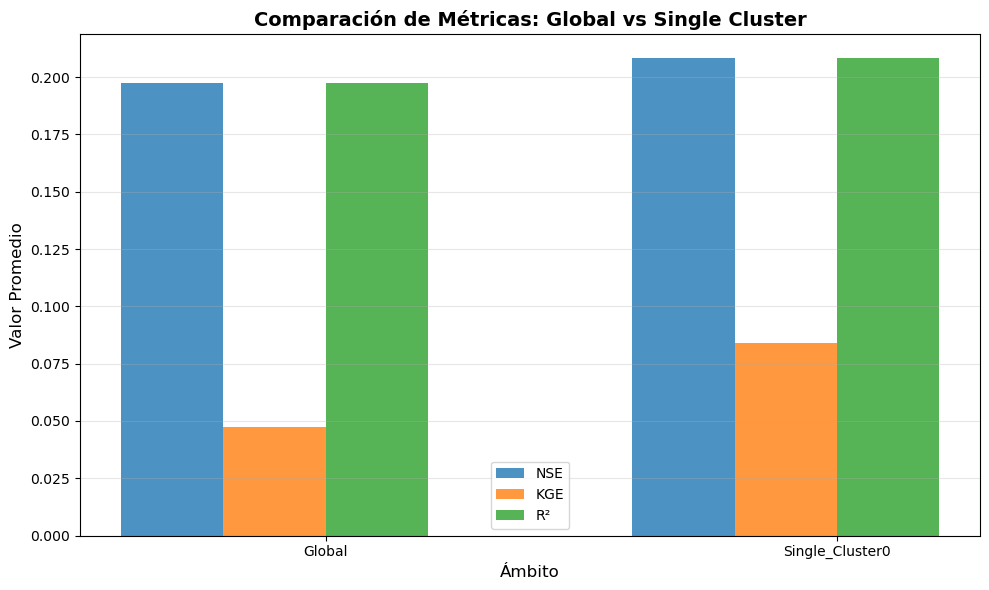

✓ Figura guardada: comparison_global_vs_single.png


In [14]:
# Comparación de métricas entre Global y Single Cluster
comparison = []

for ambito in ['Global', 'Single_Cluster0']:
    df_subset = results_df[results_df['Ámbito'] == ambito]
    comparison.append({
        'Ámbito': ambito,
        'NSE Promedio': df_subset['NSE'].mean(),
        'KGE Promedio': df_subset['KGE'].mean(),
        'R² Promedio': df_subset['R²'].mean(),
        'RMSE Promedio': df_subset['RMSE'].mean()
    })

df_comparison = pd.DataFrame(comparison)
print('\nComparación de métricas promedio:')
display(df_comparison.round(3))

# Visualización
fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(df_comparison))
width = 0.2

ax.bar(x - width*1.5, df_comparison['NSE Promedio'], width, label='NSE', alpha=0.8)
ax.bar(x - width*0.5, df_comparison['KGE Promedio'], width, label='KGE', alpha=0.8)
ax.bar(x + width*0.5, df_comparison['R² Promedio'], width, label='R²', alpha=0.8)

ax.set_xlabel('Ámbito', fontsize=12)
ax.set_ylabel('Valor Promedio', fontsize=12)
ax.set_title('Comparación de Métricas: Global vs Single Cluster', fontsize=14, weight='bold')
ax.set_xticks(x)
ax.set_xticklabels(df_comparison['Ámbito'])
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
ax.axhline(y=0, color='black', linestyle='-', linewidth=0.5)

plt.tight_layout()
plt.savefig(os.path.join(OUT_PATH, 'comparison_global_vs_single.png'), dpi=150, bbox_inches='tight')
plt.show()
print('✓ Figura guardada: comparison_global_vs_single.png')

## Visualización: Heatmap NSE/KGE (Global)

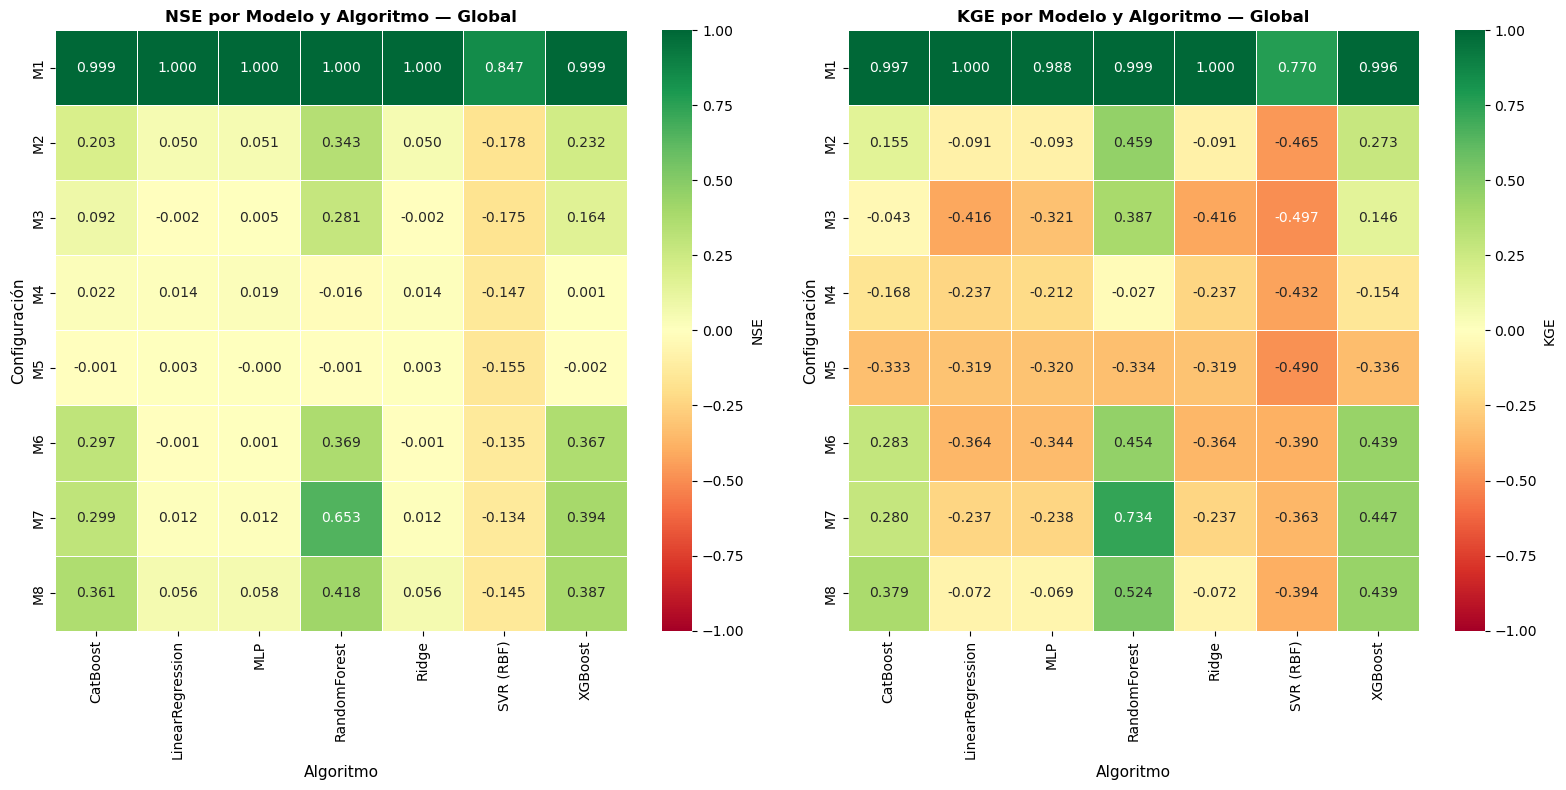

✓ Figura guardada: heatmap_nse_kge_global.png


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

for ax, metric in zip(axes, ['NSE', 'KGE']):
    hm = df_global.pivot_table(index='Config', columns='Algoritmo', values=metric).round(3)
    sns.heatmap(hm, annot=True, fmt='.3f', cmap='RdYlGn', center=0,
                vmin=-1, vmax=1, linewidths=0.5, ax=ax, cbar_kws={'label': metric})
    ax.set_title(f'{metric} por Modelo y Algoritmo — Global', fontsize=12, weight='bold')
    ax.set_ylabel('Configuración', fontsize=11)
    ax.set_xlabel('Algoritmo', fontsize=11)

plt.tight_layout()
plt.savefig(os.path.join(OUT_PATH, 'heatmap_nse_kge_global.png'), dpi=150, bbox_inches='tight')
plt.show()
print('✓ Figura guardada: heatmap_nse_kge_global.png')

## Guardar Resultados Completos

In [16]:
# Guardar resultados completos
results_df['Num.'] = range(1, len(results_df) + 1)

# Reordenar columnas para coincidir con template
results_output = results_df[[
    'Num.', 'Config', 'Descripción', 'Features', 'Ámbito', 'Algoritmo',
    'R²', 'RMSE', 'MAE', 'NSE', 'KGE', 'PBIAS_%', 'MAPE_%', 'n_samples'
]].copy()

# Guardar con timestamp
timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
csv_path = os.path.join(OUT_PATH, f'results_complete_{file_suffix}_{timestamp}.csv')
results_output.to_csv(csv_path, index=False, sep=';', encoding='utf-8')
print(f'✓ Tabla completa guardada en: {csv_path}')

# Guardar también en formato template (sin timestamp)
template_path = os.path.join(OUT_PATH, f'results_complete_{file_suffix}_.csv')
results_output.to_csv(template_path, index=False, sep=';', encoding='utf-8')
print(f'✓ Resultados guardados en formato template: {template_path}')

print(f'\nTotal de modelos ejecutados: {len(results_output)}')
print(f'\nResumen de métricas promedio por algoritmo:')
display(results_df.groupby('Algoritmo')[['R²', 'RMSE', 'NSE', 'KGE', 'PBIAS_%']].mean().round(3))

✓ Tabla completa guardada en: ../output/3_4-predictive-models/results_complete_escenario_1_bis_single_cluster_20260306_135708.csv
✓ Resultados guardados en formato template: ../output/3_4-predictive-models/results_complete_escenario_1_bis_single_cluster_.csv

Total de modelos ejecutados: 112

Resumen de métricas promedio por algoritmo:


,R²,RMSE,NSE,KGE,PBIAS_%
Algoritmo,,,,,
CatBoost,0.293,520.455,0.293,0.211,-0.031
LinearRegression,0.145,571.911,0.145,-0.074,-0.348
MLP,0.150,572.164,0.150,-0.045,0.213
RandomForest,0.379,481.259,0.379,0.402,-0.270
Ridge,0.145,571.936,0.145,-0.074,-0.348
SVR (RBF),-0.012,648.809,-0.012,-0.253,50.884
XGBoost,0.320,509.414,0.320,0.293,0.012


## Resumen Final

Los modelos han sido ejecutados con:
- **Cluster único** con las 19 cuencas del Ebro
- **8 configuraciones** de modelos (M1-M8)
- **2 ámbitos**: Global y Single_Cluster0 (idénticos en composición)
- **Múltiples algoritmos**: LinearRegression, Ridge, RandomForest, XGBoost, CatBoost, SVR, MLP
- **7 métricas**: R², RMSE, MAE, NSE, KGE, PBIAS%, MAPE%
- **Total de modelos ejecutados**: 112 (8 configs × 2 ámbitos × 7 algoritmos)

### Observación importante:
Los resultados de "Global" y "Single_Cluster0" serán idénticos ya que ambos ámbitos contienen exactamente las mismas 49,665 observaciones de todas las cuencas. Esta configuración permite validar la consistencia del framework de modelado.

Los resultados se han guardado en `notebooks/output/3_4-predictive-models/results_complete.csv`